# Task 5 — Detailed Exploratory Data Analysis (Unsupervised Anomaly Detection)

**Problem**: Unsupervised binary anomaly detection (`0` = normal, `1` = anomaly) across `25,889` player accounts observed over 4 time periods, evaluated by **Binary $F_3$ score** (recall is weighted 9× higher than precision).

Because **no training labels exist**, EDA is the core of the solution. This notebook visually uncovers every anomaly subtype step-by-step and directly derives the detector in `task5.ipynb`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find_data_dir(subdir: str) -> str:
    for p in [os.path.join("..", "cpe342-kaggle-main", subdir), os.path.join("cpe342-kaggle-main", subdir)]:
        if os.path.isdir(p):
            return os.path.abspath(p)
    hits = glob.glob(f"/kaggle/input/**/{subdir}/test.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"Dataset not found for {subdir}.")

DATA_DIR = find_data_dir("05_anomaly_detection")
X = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
P = [1, 2, 3, 4]
STATIC = ["behavior_stability", "account_age_days"]
mean4 = lambda b: X[[f"{b}_{p}" for p in P]].astype(float).mean(axis=1).values
cols_of = lambda b: [b] if b in STATIC else [f"{b}_{p}" for p in P]
inbox = lambda b, lo, hi: (((X[cols_of(b)].values.astype(float) >= lo) & (X[cols_of(b)].values.astype(float) <= hi)) | np.isnan(X[cols_of(b)].values.astype(float))).all(axis=1)

print(f"Dataset shape: {X.shape[0]:,} accounts x {X.shape[1]} columns (4 time periods + 2 static features)")
print(f"Overall missing rate: {X.isna().mean().mean()*100:.2f}% | behavior_stability missing: {X['behavior_stability'].isna().mean()*100:.2f}%")

Dataset shape: 25,889 accounts x 123 columns (4 time periods + 2 static features)
Overall missing rate: 4.84% | behavior_stability missing: 4.86%


## Step 1: Abrupt Temporal Shocks & Geolocation Jumps (Periods 3–4 vs. 1–2)

**What we check**: Do compromised/takeover accounts exhibit sudden jumps in login location or multi-metric behavioral shifts in periods 3–4 compared to their baseline in periods 1–2?

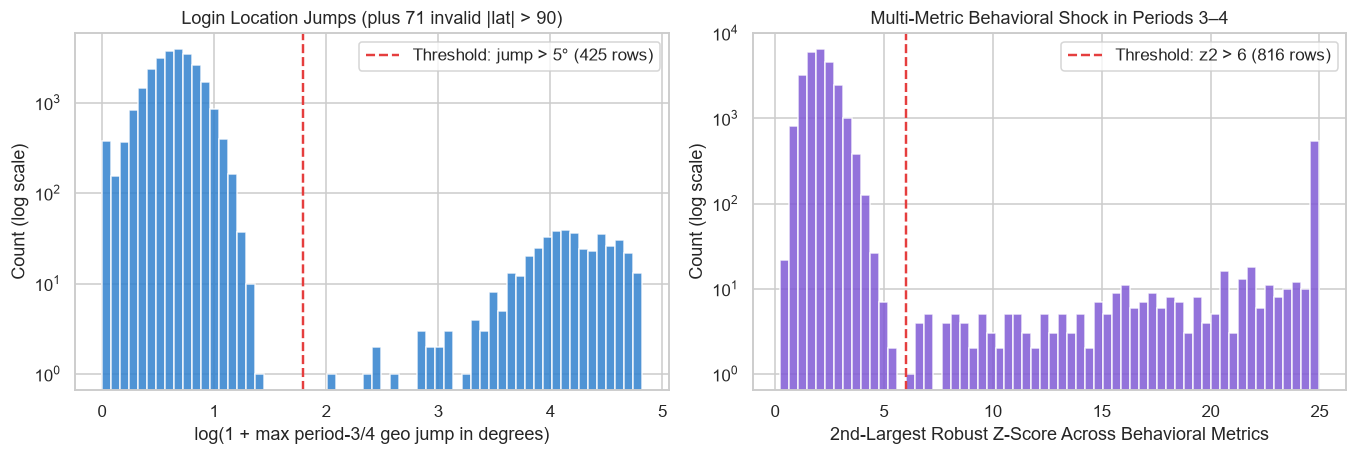

Combined shock/geo rule flags: 827 accounts


In [2]:
lat = np.stack([X[f"login_lat_{p}"] for p in P], axis=1).astype(float)
lon = np.stack([X[f"login_lon_{p}"] for p in P], axis=1).astype(float)
bad_lat = (np.abs(lat) > 90).any(axis=1)
lt = np.where(np.abs(lat) > 90, np.nan, lat)
hl, hn = np.nanmean(lt[:, :2], axis=1), np.nanmean(lon[:, :2], axis=1)
jump = np.nan_to_num(np.nanmax(np.hypot(lt[:, 2:] - hl[:, None], (lon[:, 2:] - hn[:, None] + 180) % 360 - 180), axis=1))

bases = sorted({c[:-2] for c in X.columns if c[-2:] in ("_1", "_2", "_3", "_4")} - {"login_lat", "login_lon"})
Z = []
for b in bases:
    m = X[[f"{b}_{p}" for p in P]].astype(float).values
    ch = np.nanmax(np.abs(m[:, 2:] - np.nanmean(m[:, :2], axis=1, keepdims=True)), axis=1)
    med = np.nanmedian(ch)
    mad = 1.4826 * np.nanmedian(np.abs(ch - med)) + 1e-9
    Z.append((ch - med) / mad)
z2 = np.sort(np.nan_to_num(np.stack(Z, axis=1)), axis=1)[:, -2]
rule = (jump > 5) | bad_lat | (z2 > 6)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

axes[0].hist(np.log1p(jump), bins=60, color="#3182ce", alpha=0.85, edgecolor="white")
axes[0].axvline(np.log1p(5.0), color="#e53e3e", linestyle="--", lw=1.6, label=f"Threshold: jump > 5° ({(jump > 5).sum()} rows)")
axes[0].set_yscale("log")
axes[0].set_xlabel("log(1 + max period-3/4 geo jump in degrees)")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title(f"Login Location Jumps (plus {bad_lat.sum()} invalid |lat| > 90)")
axes[0].legend()

axes[1].hist(np.clip(z2, 0, 25), bins=60, color="#805ad5", alpha=0.85, edgecolor="white")
axes[1].axvline(6.0, color="#e53e3e", linestyle="--", lw=1.6, label=f"Threshold: z2 > 6 ({(z2 > 6).sum()} rows)")
axes[1].set_yscale("log")
axes[1].set_xlabel("2nd-Largest Robust Z-Score Across Behavioral Metrics")
axes[1].set_ylabel("Count (log scale)")
axes[1].set_title("Multi-Metric Behavioral Shock in Periods 3–4")
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Combined shock/geo rule flags: {rule.sum():,} accounts")

**Insight 1**:
- Normal accounts stay close to their period-1/2 home coordinates (jump $< 1^\circ$) and rarely show large multi-metric changes ($z_2 < 4$).
- A distinct long-tail population shows sudden geolocation jumps ($> 5^\circ$), corrupted latitudes ($|\text{lat}| > 90$), or simultaneous spikes across $\ge 2$ behavioral metrics ($z_2 > 6$).

**Decision**:
- Define Stage-1 shock rule: `(jump > 5) | bad_lat | (z2 > 6)`.

## Step 2: Clean Distribution Gaps Revealing 4 Stationary Anomaly Clusters

**What we check**: Are there stationary (all-4-period) anomalous subpopulations separated by empty gaps from normal accounts?

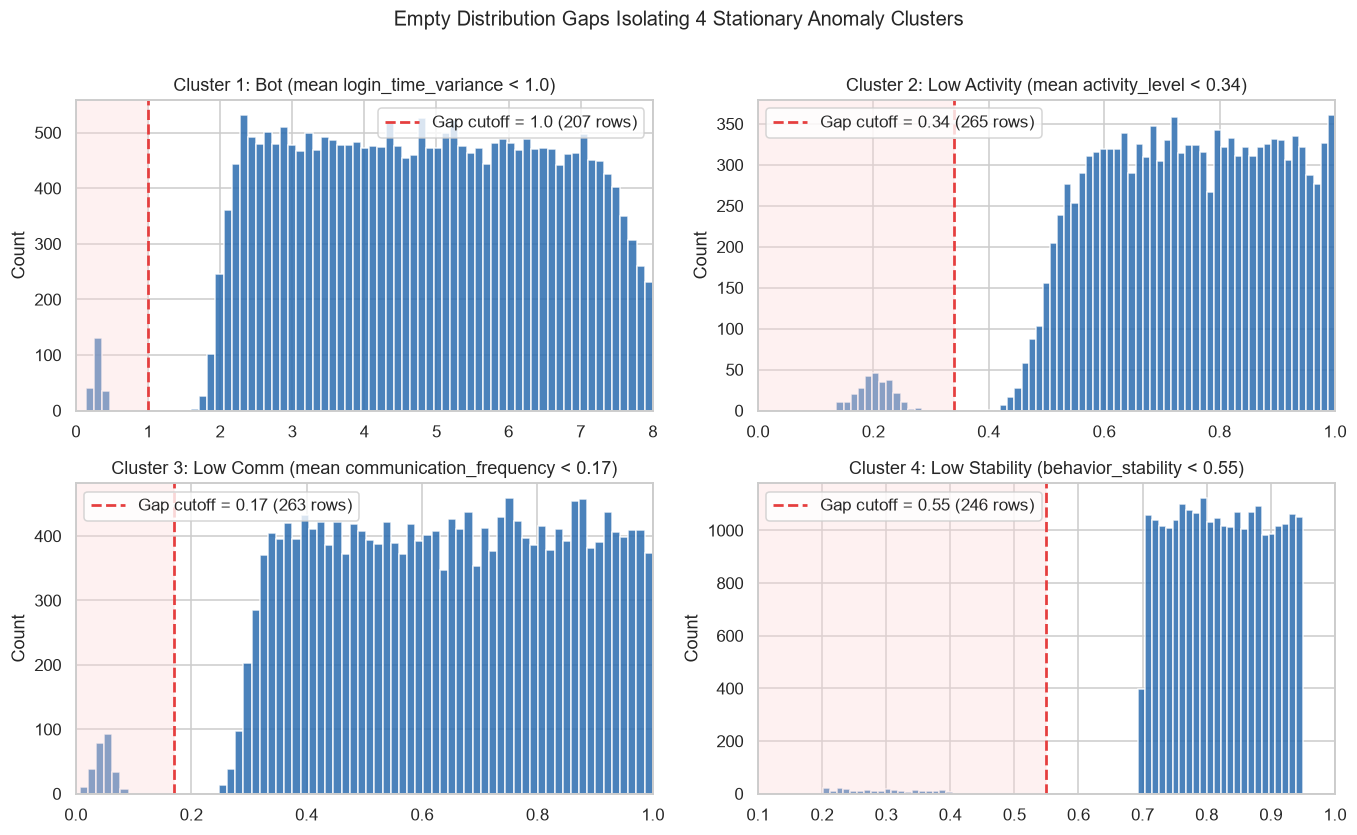

In [3]:
bot = mean4("login_time_variance") < 1.0
lowact = mean4("activity_level") < 0.34
lowcomm = mean4("communication_frequency") < 0.17
lowstab = X["behavior_stability"].values < 0.55
union_base = rule | bot | lowact | lowcomm | lowstab

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.5))
panels = [
    (mean4("login_time_variance"), 1.0, (0, 8), "Cluster 1: Bot (mean login_time_variance < 1.0)", bot.sum()),
    (mean4("activity_level"), 0.34, (0, 1.0), "Cluster 2: Low Activity (mean activity_level < 0.34)", lowact.sum()),
    (mean4("communication_frequency"), 0.17, (0, 1.0), "Cluster 3: Low Comm (mean communication_frequency < 0.17)", lowcomm.sum()),
    (X["behavior_stability"].values, 0.55, (0.1, 1.0), "Cluster 4: Low Stability (behavior_stability < 0.55)", lowstab.sum()),
]

for ax, (vals, thr, xlim, title, cnt) in zip(axes.ravel(), panels):
    v = vals[~np.isnan(vals)]
    ax.hist(v[(v >= xlim[0]) & (v <= xlim[1])], bins=70, color="#2b6cb0", alpha=0.85, edgecolor="white")
    ax.axvline(thr, color="#e53e3e", linestyle="--", lw=1.8, label=f"Gap cutoff = {thr} ({cnt} rows)")
    ax.axvspan(xlim[0], thr, color="#fed7d7", alpha=0.35)
    ax.set_xlim(*xlim)
    ax.set_title(title)
    ax.set_ylabel("Count")
    ax.legend()

plt.suptitle("Empty Distribution Gaps Isolating 4 Stationary Anomaly Clusters", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Insight 2**:
- All 4 metrics show **visually obvious empty gaps** cleanly separating small stationary anomaly clusters (`bot`, `lowact`, `lowcomm`, `lowstab`) from the bulk normal distribution.

**Decision**:
- Flag each cluster using its exact gap cutoff instead of a generic anomaly score (which would blur these crisp boundaries with normal-distribution tails).

## Step 3: Multi-Period Box Anomaly (`acckda`) & Hidden `lowstab` Recovery

**What we check**:
1. Outside the Stage-1 union, does a 5th stationary anomaly hide inside a joint multi-period box (`performance_stability in [0.85, 0.95]`, `kda_std in [0.7, 1.0]`, `accuracy_std in [9, 12]`)?
2. Among accounts with `behavior_stability = NaN` (~5%), can we recover hidden `lowstab` accounts using their companion box (`purchase_frequency in [3, 6]` & `account_age_days in [800, 1500]`) and secondary features (`login_count`, `purchase_frequency` std)?

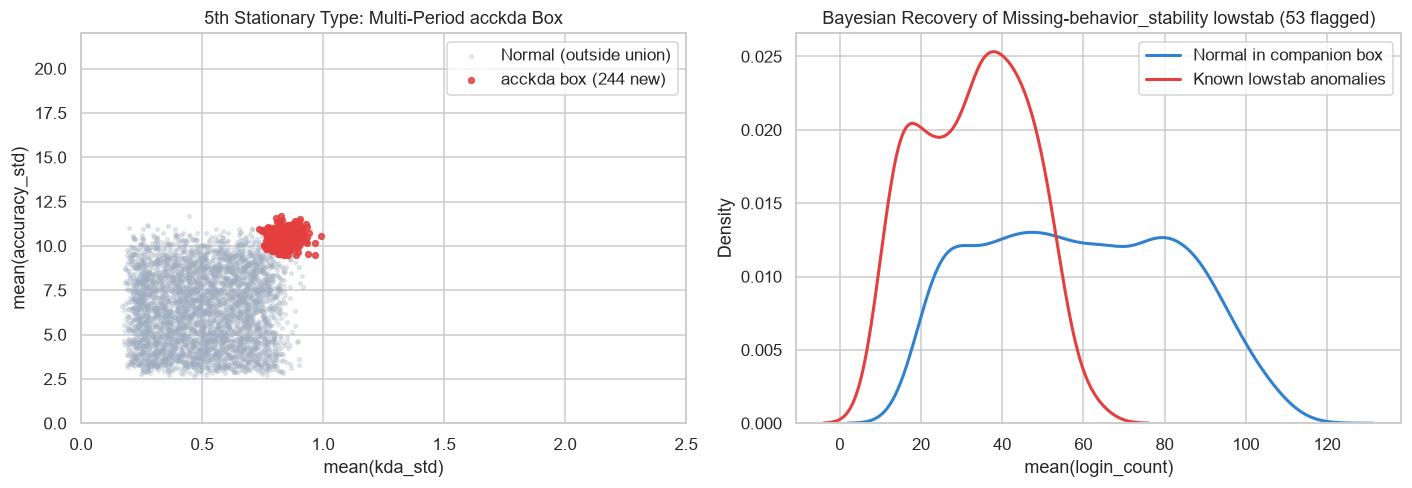

In [4]:
acckda = inbox("performance_stability", 0.85, 0.95) & inbox("kda_std", 0.7, 1.0) & inbox("accuracy_std", 9.0, 12.0)
acckda_new = acckda & ~union_base

bsn = X["behavior_stability"].isna().values
pf_box = inbox("purchase_frequency", 3.0, 6.0)
age_box = inbox("account_age_days", 800.0, 1500.0)
nr = ~union_base & ~bsn
cand = bsn & ~union_base & pf_box & age_box
nor = nr & pf_box & age_box & (X["behavior_stability"].values >= 0.6)
lm = mean4("login_count")
ps = X[[f"purchase_frequency_{p}" for p in P]].std(axis=1).values

def logpdf(v, ref, bins):
    h, _ = np.histogram(ref[~np.isnan(ref)], bins=bins)
    h = (h + 0.5) / (h.sum() + 0.5 * len(h)) / np.diff(bins)
    o = np.log(h[np.clip(np.digitize(v, bins) - 1, 0, len(h) - 1)])
    o[np.isnan(v)] = 0.0
    return o

LLR = (logpdf(lm, lm[lowstab], np.linspace(0, 130, 27)) - logpdf(lm, lm[nor], np.linspace(0, 130, 27))
       + logpdf(ps, ps[lowstab], np.linspace(0, 2.5, 26)) - logpdf(ps, ps[nor], np.linspace(0, 2.5, 26)))
prior = 14.0 / cand.sum()
post = np.where(cand, 1.0 / (1.0 + np.exp(-(LLR + np.log(prior / (1.0 - prior))))), 0.0)
lsnan_flag = post > 0.10

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Panel A: acckda box in (kda_std, accuracy_std) space
out_mask = ~union_base
m_kda = mean4("kda_std")
m_acc = mean4("accuracy_std")
bg = np.where(out_mask & ~acckda_new)[0]
bg_s = np.random.RandomState(42).choice(bg, size=4000, replace=False)
axes[0].scatter(m_kda[bg_s], m_acc[bg_s], s=6, alpha=0.25, color="#a0aec0", label="Normal (outside union)")
axes[0].scatter(m_kda[acckda_new], m_acc[acckda_new], s=14, alpha=0.85, color="#e53e3e", label=f"acckda box ({acckda_new.sum()} new)")
axes[0].set_xlim(0, 2.5)
axes[0].set_ylim(0, 22)
axes[0].set_xlabel("mean(kda_std)")
axes[0].set_ylabel("mean(accuracy_std)")
axes[0].set_title("5th Stationary Type: Multi-Period acckda Box")
axes[0].legend()

# Panel B: login_count separation for lowstab vs normal-in-box
sns.kdeplot(lm[nor][~np.isnan(lm[nor])], ax=axes[1], color="#3182ce", lw=2, label="Normal in companion box")
sns.kdeplot(lm[lowstab][~np.isnan(lm[lowstab])], ax=axes[1], color="#e53e3e", lw=2, label="Known lowstab anomalies")
axes[1].set_xlabel("mean(login_count)")
axes[1].set_title(f"Bayesian Recovery of Missing-behavior_stability lowstab ({lsnan_flag.sum()} flagged)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 4: Final Anomaly Subtype Breakdown

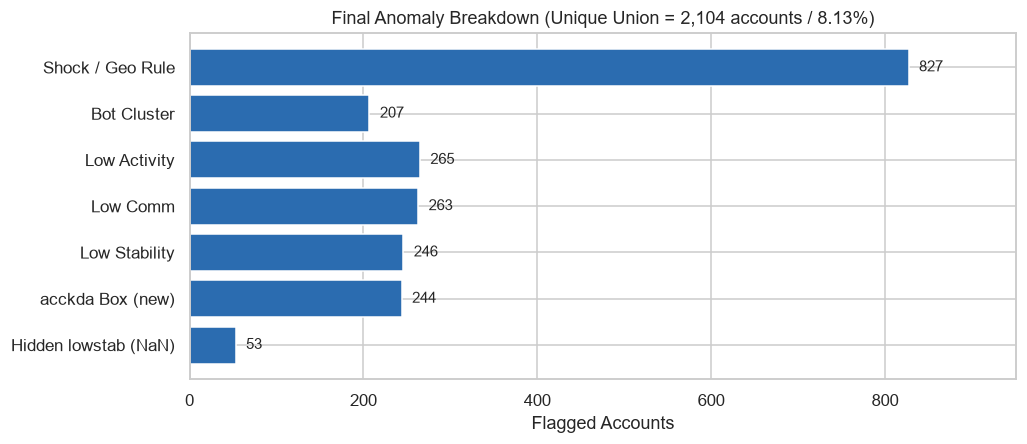

In [5]:
final_pred = union_base | acckda | lsnan_flag
breakdown = pd.Series({
    "Shock / Geo Rule": int(rule.sum()),
    "Bot Cluster": int(bot.sum()),
    "Low Activity": int(lowact.sum()),
    "Low Comm": int(lowcomm.sum()),
    "Low Stability": int(lowstab.sum()),
    "acckda Box (new)": int(acckda_new.sum()),
    "Hidden lowstab (NaN)": int(lsnan_flag.sum()),
})

fig, ax = plt.subplots(figsize=(9.5, 4.2))
bars = ax.barh(breakdown.index[::-1], breakdown.values[::-1], color="#2b6cb0")
for b, v in zip(bars, breakdown.values[::-1]):
    ax.text(v + 12, b.get_y() + b.get_height()/2, f"{v:,}", va="center", fontsize=9.5)
ax.set_xlim(0, breakdown.max() * 1.15)
ax.set_xlabel("Flagged Accounts")
ax.set_title(f"Final Anomaly Breakdown (Unique Union = {int(final_pred.sum()):,} accounts / {final_pred.mean()*100:.2f}%)")
plt.tight_layout()
plt.show()

## Summary: EDA Insights $\rightarrow$ Modeling Decisions (`task5.ipynb`)

| Step | EDA Finding | Decision in `task5.ipynb` |
| :--- | :--- | :--- |
| 1 | Abrupt period-3/4 geo jumps ($>5^\circ$), invalid latitudes, and multi-metric shocks ($z_2 > 6$) | Stage-1 shock/takeover rule |
| 2 | 4 empty distribution gaps in `login_time_variance`, `activity_level`, `communication_frequency`, `behavior_stability` | Exact gap-threshold stationary cluster detectors (`bot`, `lowact`, `lowcomm`, `lowstab`) |
| 3a | Tight 3-metric multi-period box (`performance_stability`, `kda_std`, `accuracy_std`) | Stage-2 `acckda` multi-period box detector |
| 3b | ~5% missing `behavior_stability` hides ~14 true `lowstab` accounts inside their companion box | Stage-3 Bayesian LLR posterior (`p > 0.10`) aligned with recall-heavy $F_3$ metric |